# 01 — Entendimento do Negócio e dos Dados
**Projeto:** Recomendador de jogos da Steam baseado no perfil recente do jogador
**Metodologia:** CRISP-DM — etapas 1 (Entendimento do Negócio) e 2 (Entendimento dos Dados)

## 1. Entendimento do Negócio
- **Problema:** a Steam tem dezenas de milhares de jogos; achar o próximo jogo parecido com o que a pessoa gosta é difícil.
- **Pergunta de pesquisa:** usar vários jogos recentes (5) gera recomendações mais coerentes do que usar apenas um jogo?
- **Mudança em relação ao seminário (feedback do professor):** incorporamos uma segunda base, com **interações reais de usuários**.
  Isso permite (a) montar perfis reais de jogadores, (b) medir a qualidade das recomendações com métricas objetivas e
  (c) comparar modelos de conteúdo com modelos colaborativos.

| Base | Fonte | Papel no projeto |
|---|---|---|
| A — Steam Games Dataset | Kaggle (Hubert Sidorowicz) | metadados: gêneros, categorias, tags, avaliações |
| B — Game Recommendations on Steam | Kaggle (Anton Kozyriev) | interações usuário × jogo (recomendou? horas? data) |

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, carregamento as c, preparacao as p, graficos as g

config.criar_pastas()
g.aplicar_estilo()
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("Percentual de usuários amostrados:", config.PERCENTUAL_USUARIOS, "%")

Percentual de usuários amostrados: 15 %


## 2. Base A — metadados dos jogos

In [2]:
A = c.carregar_base_a()
print(f"Base A: {A.shape[0]:,} linhas x {A.shape[1]} colunas | {c.memoria_mb(A):,.0f} MB em memória")
A.head()

Base A: 144,981 linhas x 14 colunas | 120 MB em memória


,app_id,name,release_date,price,estimated_owners,developers,publishers,genres,categories,tags,positive,negative,recommendations,average_playtime_forever
0,2527550,Roll The Bones,2026-07-28,9.9900,"0 .. 20,000","[""Shrimp Industries""]","[""Proteus Interactive""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",[],0,0,NaN,0
1,2806050,Halo: Campaign Evolved,2026-07-28,49.9900,"0 .. 20,000","[""Halo Studios""]","[""Xbox Game Studios""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",[],0,0,"4,936.0000",0
2,2789980,Sinned Arena,2026-07-28,8.9900,"0 .. 20,000","[""xDenny""]","[""xDenny""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",[],0,0,NaN,0
3,3041730,Go North,2026-07-28,14.9900,"0 .. 20,000","[""gazuntype""]","[""gazuntype""]","[{""id"": ""25"", ""description"": ""Adventure""}, {""i...","[{""id"": 2, ""description"": ""Single-player""}, {""...",[],0,0,NaN,0
4,3044420,Rabbit Comes Home,2026-07-28,6.9900,"0 .. 20,000","[""ZIPSTED""]","[""ZIPSTED""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",[],0,0,NaN,0


In [3]:
faltantes_a = c.resumo_colunas(A)
faltantes_a.to_csv(config.RESULTADOS / "tabela_colunas_base_a.csv")
faltantes_a

,tipo,nao_nulos,faltantes,faltantes_%,valores_unicos
app_id,int64,144981,0,0.0000,144981
name,object,144965,16,0.0100,143478
release_date,object,144899,82,0.0600,5373
price,float64,143611,1370,0.9400,987
estimated_owners,object,144981,0,0.0000,27
developers,object,144981,0,0.0000,86078
publishers,object,144981,0,0.0000,77343
genres,object,144981,0,0.0000,4243
categories,object,144981,0,0.0000,22816
tags,object,144981,0,0.0000,80692


In [4]:
problemas_a = {
    "linhas": len(A),
    "app_id_duplicados": int(A["app_id"].duplicated().sum()),
    "nome_vazio": int(A["name"].isna().sum()),
    "sem_genero": int(A["genres"].map(p.parse_lista).map(len).eq(0).sum()),
    "sem_tags": int(A["tags"].map(p.parse_lista).map(len).eq(0).sum()) if "tags" in A else None,
    "sem_nenhuma_avaliacao": int(((A["positive"].fillna(0) + A["negative"].fillna(0)) == 0).sum()),
}
problemas_a

{'linhas': 144981,
 'app_id_duplicados': 0,
 'nome_vazio': 16,
 'sem_genero': 8433,
 'sem_tags': 61512,
 'sem_nenhuma_avaliacao': 61904}

### Gêneros mais frequentes (figura usada no seminário, agora reproduzível em código)

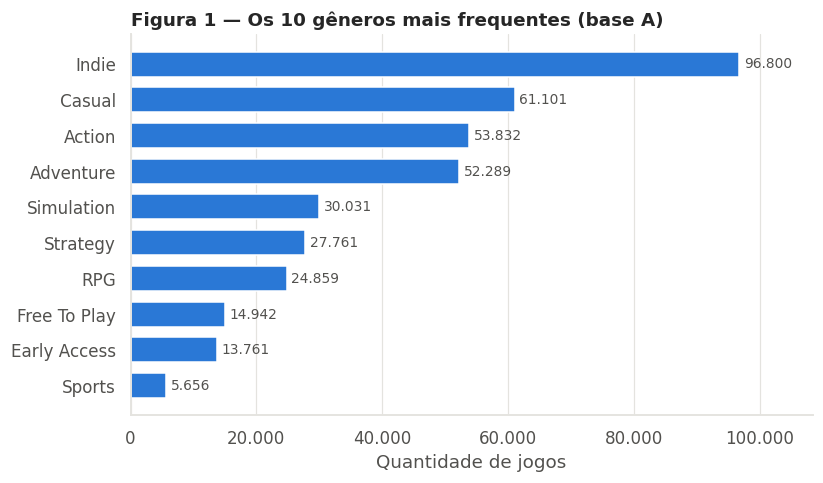

In [5]:
generos = (A.drop_duplicates("app_id")["genres"].map(p.parse_lista)
             .explode().dropna().value_counts().head(10).sort_values())
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(generos.index, generos.values, color=g.AZUL, height=0.7)
g.rotular_barras(ax, horizontal=True)
ax.set_title("Figura 1 — Os 10 gêneros mais frequentes (base A)")
ax.set_xlabel("Quantidade de jogos")
g.eixo_br(ax, "x")
ax.grid(axis="y", visible=False)
g.salvar(fig, "fig01_generos_top10")
plt.show()

### Volume de avaliações por jogo — justificativa para um volume mínimo no filtro de qualidade

count     144,981.0000
mean        1,027.2790
std        30,016.6934
min             0.0000
25%             0.0000
50%             3.0000
75%            33.0000
90%           270.0000
99%        12,681.2000
max     8,815,087.0000
dtype: float64
Jogos com menos de 50 avaliações: 78.8%


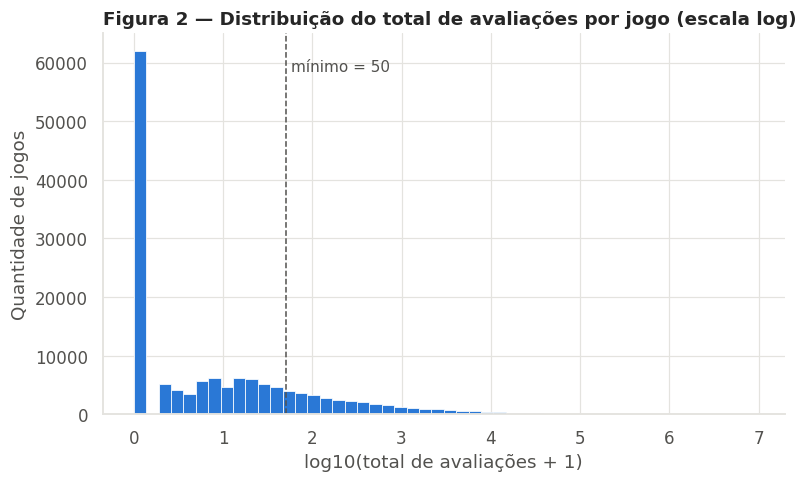

In [6]:
total_av = (A["positive"].fillna(0) + A["negative"].fillna(0))
print(total_av.describe(percentiles=[.25, .5, .75, .9, .99]))
print(f"Jogos com menos de {config.MIN_AVALIACOES_QUALIDADE} avaliações: {(total_av < config.MIN_AVALIACOES_QUALIDADE).mean():.1%}")

fig, ax = plt.subplots()
ax.hist(np.log10(total_av + 1), bins=50, color=g.AZUL, edgecolor="white", linewidth=0.5)
ax.axvline(np.log10(config.MIN_AVALIACOES_QUALIDADE + 1), color=g.TEXTO_SECUNDARIO, ls="--", lw=1)
ax.text(np.log10(config.MIN_AVALIACOES_QUALIDADE + 1) + 0.05, ax.get_ylim()[1] * 0.9,
        f"mínimo = {config.MIN_AVALIACOES_QUALIDADE}", color=g.TEXTO_SECUNDARIO)
ax.set_title("Figura 2 — Distribuição do total de avaliações por jogo (escala log)")
ax.set_xlabel("log10(total de avaliações + 1)")
ax.set_ylabel("Quantidade de jogos")
g.salvar(fig, "fig02_distribuicao_avaliacoes")
plt.show()

### Faixas de taxa negativa (regra de negócio apresentada no seminário)

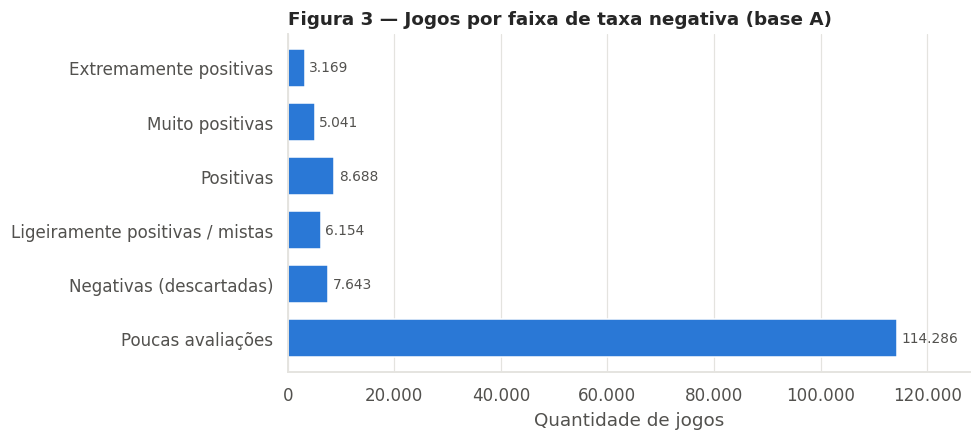

,count
Extremamente positivas,3169
Muito positivas,5041
Positivas,8688
Ligeiramente positivas / mistas,6154
Negativas (descartadas),7643
Poucas avaliações,114286


In [7]:
taxa = np.where(total_av > 0, A["negative"].fillna(0) / total_av.replace(0, np.nan), np.nan)
faixas = pd.Series([p.classificar_taxa_negativa(t, n) for t, n in zip(np.nan_to_num(taxa, nan=1), total_av)])
ordem = ["Extremamente positivas", "Muito positivas", "Positivas",
         "Ligeiramente positivas / mistas", "Negativas (descartadas)", "Poucas avaliações"]
contagem_faixas = faixas.value_counts().reindex(ordem, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(contagem_faixas.index[::-1], contagem_faixas.values[::-1], color=g.AZUL, height=0.7)
g.rotular_barras(ax, horizontal=True)
ax.set_title("Figura 3 — Jogos por faixa de taxa negativa (base A)")
ax.set_xlabel("Quantidade de jogos")
g.eixo_br(ax, "x")
ax.grid(axis="y", visible=False)
g.salvar(fig, "fig03_faixas_taxa_negativa")
plt.show()
contagem_faixas

## 3. Base B — interações de usuários

In [8]:
gb = c.carregar_b_games()
users = c.carregar_b_users()
meta = c.carregar_b_metadata()
recs, resumo_recs = c.carregar_recomendacoes()

print(f"games.csv:          {gb.shape}")
print(f"users.csv:          {users.shape}")
print(f"games_metadata:     {meta.shape}")
print(f"recommendations:    {resumo_recs['linhas_base_completa']:,} linhas na base completa")
print(f"amostra ({config.PERCENTUAL_USUARIOS}% usuários): {len(recs):,} linhas | {c.memoria_mb(recs):,.0f} MB")
recs.head()

games.csv:          (50872, 13)
users.csv:          (14306064, 3)
games_metadata:     (50872, 3)
recommendations:    41,154,794 linhas na base completa
amostra (15% usuários): 6,166,612 linhas | 129 MB


,app_id,date,is_recommended,hours,user_id
0,730,2021-11-30,False,157.5000,63209
1,255710,2021-05-21,True,18.7000,354512
2,304390,2017-03-23,False,180.6000,397000
3,438100,2020-09-10,True,8.1000,912612
4,1248130,2022-07-18,True,19.2000,1093813


In [9]:
tab_b = pd.concat({"games.csv": c.resumo_colunas(gb), "recommendations.csv": c.resumo_colunas(recs)})
tab_b.to_csv(config.RESULTADOS / "tabela_colunas_base_b.csv")
tab_b

tipo  nao_nulos  faltantes  \
games.csv           app_id                   int64      50872          0   
                    title                   object      50872          0   
                    date_release    datetime64[ns]      50872          0   
                    win                       bool      50872          0   
                    mac                       bool      50872          0   
                    linux                     bool      50872          0   
                    rating                  object      50872          0   
                    positive_ratio           int64      50872          0   
                    user_reviews             int64      50872          0   
                    price_final            float64      50872          0   
                    price_original         float64      50872          0   
                    discount               float64      50872          0   
                    steam_deck                bool      50872          0   
recommendations.csv app_id                   int32    6166612          0   
                    date            datetime64[ns]    6166612          0   
                    is_recommended            bool    6166612          0   
                    hours                  float32    6166612          0   
                    user_id                  int32    6166612          0   

                                    faltantes_%  valores_unicos  
games.csv           app_id               0.0000           50872  
                    title                0.0000           50751  
                    date_release         0.0000            4292  
                    win                  0.0000               2  
                    mac                  0.0000               2  
                    linux                0.0000               2  
                    rating               0.0000               9  
                    positive_ratio       0.0000             100  
                    user_reviews         0.0000            4847  
                    price_final          0.0000             436  
                    price_original       0.0000             183  
                    discount             0.0000              75  
                    steam_deck           0.0000               2  
recommendations.csv app_id               0.0000           33990  
                    date                 0.0000            4444  
                    is_recommended       0.0000               2  
                    hours                0.0000           10001  
                    user_id              0.0000         2067166

### Desbalanceamento da variável `is_recommended`
A grande maioria das avaliações é positiva. Isso orienta a decisão de modelagem: tratamos o problema como
**feedback implícito positivo** (o usuário recomendou o jogo = gostou), e não como classificação binária,
onde a classe negativa seria minoritária e pouco informativa para recomendar.

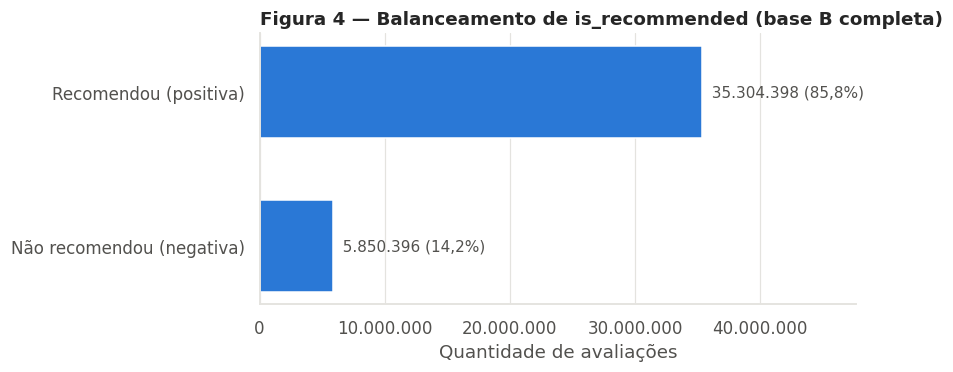

In [10]:
pos = resumo_recs["positivas_base_completa"]
neg = resumo_recs["linhas_base_completa"] - pos
bal = pd.Series({"Recomendou (positiva)": pos, "Não recomendou (negativa)": neg})

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(bal.index[::-1], bal.values[::-1], color=g.AZUL, height=0.6)
for i, v in enumerate(bal.values[::-1]):
    ax.text(v, i, f"  {g.br(v)} ({g.br(v / bal.sum() * 100, '{:.1f}')}%)", va="center", color=g.TEXTO_SECUNDARIO)
ax.margins(x=0.35)
ax.set_title("Figura 4 — Balanceamento de is_recommended (base B completa)")
ax.set_xlabel("Quantidade de avaliações")
g.eixo_br(ax, "x")
ax.grid(axis="y", visible=False)
g.salvar(fig, "fig04_balanceamento_is_recommended")
plt.show()

### Interações por usuário — a maioria avalia poucos jogos (cauda longa)

count   1,899,173.0000
mean            2.7881
std             6.7164
min             1.0000
50%             1.0000
75%             3.0000
90%             5.0000
99%            22.0000
max         3,023.0000
dtype: float64
Usuários com >= 8 jogos recomendados: 6.2%


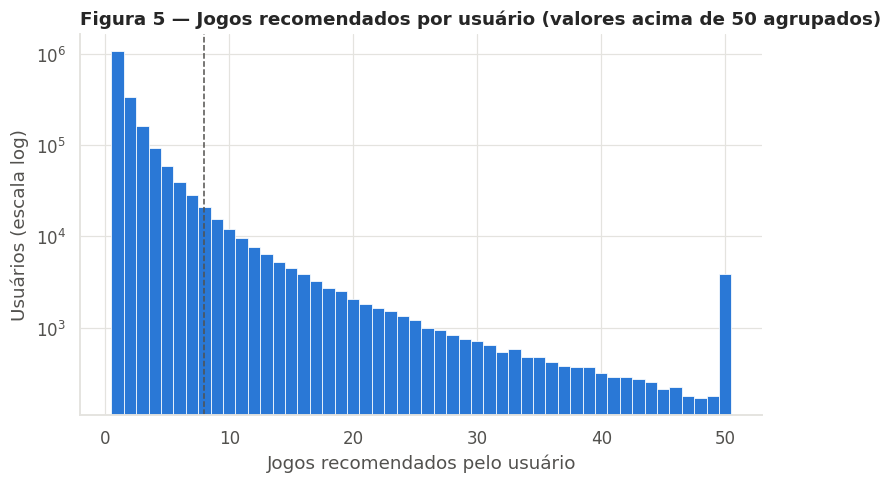

In [11]:
por_usuario = recs[recs["is_recommended"]].groupby("user_id").size()
print(por_usuario.describe(percentiles=[.5, .75, .9, .99]))
print(f"Usuários com >= {config.MIN_INTERACOES_USUARIO} jogos recomendados: "
      f"{(por_usuario >= config.MIN_INTERACOES_USUARIO).mean():.1%}")

fig, ax = plt.subplots()
ax.hist(por_usuario.clip(upper=50), bins=np.arange(0.5, 51.5, 1), color=g.AZUL, edgecolor="white", linewidth=0.5)
ax.axvline(config.MIN_INTERACOES_USUARIO, color=g.TEXTO_SECUNDARIO, ls="--", lw=1)
ax.set_yscale("log")
ax.set_title("Figura 5 — Jogos recomendados por usuário (valores acima de 50 agrupados)")
ax.set_xlabel("Jogos recomendados pelo usuário")
ax.set_ylabel("Usuários (escala log)")
g.salvar(fig, "fig05_interacoes_por_usuario")
plt.show()

### Concentração da popularidade — poucos jogos recebem a maior parte das interações

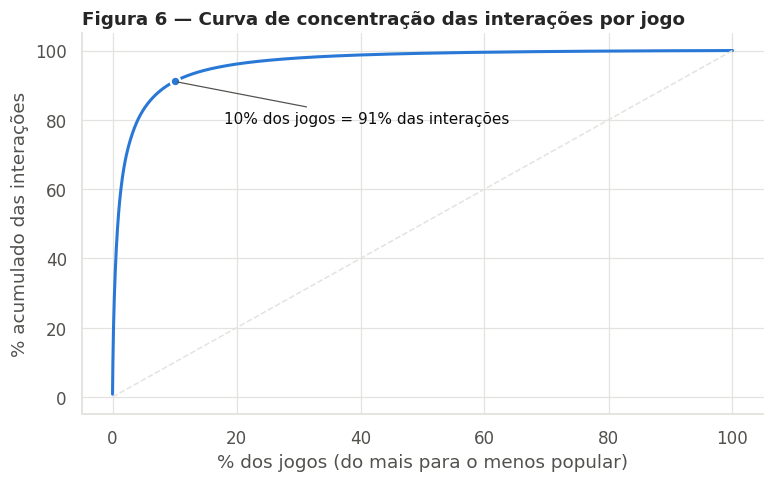

In [12]:
por_jogo = recs[recs["is_recommended"]].groupby("app_id").size().sort_values(ascending=False)
x = np.arange(1, len(por_jogo) + 1) / len(por_jogo) * 100
y = por_jogo.cumsum().to_numpy() / por_jogo.sum() * 100
top10 = y[int(len(y) * 0.10) - 1]

fig, ax = plt.subplots()
ax.plot(x, y, color=g.AZUL)
ax.plot([0, 100], [0, 100], color=g.GRADE, lw=1, ls="--")
ax.scatter([10], [top10], color=g.AZUL, s=40, zorder=3, edgecolor="white", linewidth=1.5)
ax.annotate(f"10% dos jogos = {top10:.0f}% das interações", (10, top10), xytext=(18, top10 - 12),
            color=g.TEXTO, arrowprops=dict(arrowstyle="-", color=g.TEXTO_SECUNDARIO, lw=0.8))
ax.set_title("Figura 6 — Curva de concentração das interações por jogo")
ax.set_xlabel("% dos jogos (do mais para o menos popular)")
ax.set_ylabel("% acumulado das interações")
g.salvar(fig, "fig06_concentracao_popularidade")
plt.show()

## 4. Junção das bases A e B

In [13]:
cobertura = gb["app_id"].isin(A["app_id"]).mean()
tags_a = A["tags"].map(p.parse_lista).map(len) if "tags" in A else pd.Series([0])
tags_b = meta["tags"].map(p.parse_lista).map(len)
print(f"Jogos da base B encontrados na base A: {cobertura:.1%}")
print(f"Média de tags por jogo — base A: {tags_a.mean():.1f} | base B: {tags_b.mean():.1f}")

Jogos da base B encontrados na base A: 77.5%
Média de tags por jogo — base A: 8.1 | base B: 11.5


In [14]:
resumo_entendimento = {
    "base_a_linhas": int(len(A)),
    "base_a_colunas_usadas": int(A.shape[1]),
    **{f"base_a_{k}": v for k, v in problemas_a.items()},
    "base_b_jogos": int(len(gb)),
    "base_b_usuarios": int(len(users)),
    **{f"base_b_{k}": v for k, v in resumo_recs.items()},
    "cobertura_b_em_a": float(cobertura),
    "top10pct_jogos_share_interacoes": float(top10),
    "mediana_jogos_por_usuario_amostra": float(por_usuario.median()),
}
with open(config.RESULTADOS / "resumo_entendimento.json", "w", encoding="utf-8") as f:
    json.dump(resumo_entendimento, f, ensure_ascii=False, indent=2, default=float)
resumo_entendimento

{'base_a_linhas': 144981,
 'base_a_colunas_usadas': 14,
 'base_a_app_id_duplicados': 0,
 'base_a_nome_vazio': 16,
 'base_a_sem_genero': 8433,
 'base_a_sem_tags': 61512,
 'base_a_sem_nenhuma_avaliacao': 61904,
 'base_b_jogos': 50872,
 'base_b_usuarios': 14306064,
 'base_b_linhas_base_completa': 41154794,
 'base_b_positivas_base_completa': 35304398,
 'base_b_proporcao_positivas_base_completa': 0.8578441189621797,
 'base_b_percentual_usuarios_amostrados': 15,
 'base_b_linhas_amostra': 6166612,
 'cobertura_b_em_a': 0.7750825601509671,
 'top10pct_jogos_share_interacoes': 91.08631073223333,
 'mediana_jogos_por_usuario_amostra': 1.0}

## Principais achados desta etapa (preencher com os números acima para o artigo)
- **Qualidade dos dados (A):** duplicatas de `app_id`, nomes vazios e jogos sem gênero/tags → tratados na preparação.
- **Avaliações:** distribuição muito assimétrica; muitos jogos com poucas avaliações → a taxa negativa precisa de volume mínimo.
- **Desbalanceamento (B):** `is_recommended` majoritariamente positivo → modelagem como feedback implícito positivo.
- **Cauda longa:** poucos jogos concentram a maior parte das interações → baseline de popularidade é obrigatório e a cobertura do catálogo deve ser medida.
- **Junção:** a maior parte dos jogos de B existe em A → o enriquecimento com gêneros/categorias é viável.